In [1]:
# Parameters (overridden during execution)
EPOCHS = 25
RUN_ID = 1
OUT_DIR = "/kaggle/working/outputs"

In [2]:
!pip install torchinfo
!pip install --quiet torchview graphviz

In [3]:
import os
import math
import time
import random
import multiprocessing
from datetime import timedelta
from pathlib import Path
from collections import defaultdict
from concurrent.futures import ThreadPoolExecutor
from glob import glob

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from tqdm import tqdm
from IPython.display import SVG, display

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights

from timm.models.vision_transformer import VisionTransformer, PatchEmbed
from torchinfo import summary
from torchview import draw_graph

In [4]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

In [5]:
from torchvision import datasets, transforms
from torch.utils.data import random_split
from collections import Counter

In [6]:
import os
import shutil
from pathlib import Path

ZIP_PATH = "/content/archive (10).zip"
EXTRACT_PATH = "/content/lung_cancer"

# Remove previous extraction
if os.path.exists(EXTRACT_PATH):
    shutil.rmtree(EXTRACT_PATH)

# Create clean destination
os.makedirs(EXTRACT_PATH, exist_ok=True)

# Extract without interactive prompts
!unzip -oq "/content/archive (10).zip" -d /content/lung_cancer

print("Dataset extracted successfully!")

Dataset extracted successfully!


In [7]:
import os
from pathlib import Path
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

In [8]:
BASE_ROOT  = Path("/content/lung_cancer/Data")
TRAIN_ROOT = BASE_ROOT / "train"
VAL_ROOT   = BASE_ROOT / "valid"
TEST_ROOT  = BASE_ROOT / "test"

assert TRAIN_ROOT.exists(), "Train folder not found"
assert VAL_ROOT.exists(),   "Valid folder not found"
assert TEST_ROOT.exists(),  "Test folder not found"


In [9]:
from torch.utils.data import Dataset, DataLoader

# -------------------------
# PyTorch Dataset
# -------------------------
class LungDataset(Dataset):
    def __init__(self, root, transform=None):
        self.samples = []
        self.class_names = sorted([
            d for d in os.listdir(root)
            if (root / d).is_dir()
        ])
        self.class_to_idx = {c: i for i, c in enumerate(self.class_names)}
        self.transform = transform

        for cls in self.class_names:
            cls_dir = root / cls
            for img_name in os.listdir(cls_dir):
                if img_name.lower().endswith((".png", ".jpg", ".jpeg")):
                    self.samples.append(
                        (cls_dir / img_name, self.class_to_idx[cls])
                    )

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")

        if self.transform is not None:
            img = self.transform(img)

        return img, label


In [10]:
IMG_SIZE   = 224     # MUST match model input
BATCH_SIZE = 6

transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),  # shape only
    transforms.ToTensor(),                    # required by PyTorch
])


In [11]:
train_ds = LungDataset(TRAIN_ROOT, transform)
val_ds   = LungDataset(VAL_ROOT,   transform)
test_ds  = LungDataset(TEST_ROOT,  transform)


In [12]:
CLASS_NAMES = train_ds.class_names
NUM_CLASSES = len(CLASS_NAMES)

print("Detected classes:")
for i, name in enumerate(CLASS_NAMES):
    print(f"{i}: {name}")

print(f"\nNumber of classes: {NUM_CLASSES}")


Detected classes:
0: adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib
1: large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa
2: normal
3: squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa

Number of classes: 4


In [13]:
train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)


In [14]:
def show_random_images_per_class(
    dataset,
    class_names,
    n_per_class=5,
    seed=42
):
    random.seed(seed)
    torch.manual_seed(seed)

    # Extract labels
    labels = np.array([label for _, label in dataset])
    num_classes = len(class_names)

    fig, axes = plt.subplots(
        num_classes,
        n_per_class,
        figsize=(3 * n_per_class, 3 * num_classes),
        squeeze=False
    )

    for cls_idx in range(num_classes):
        cls_indices = np.where(labels == cls_idx)[0]
        selected = np.random.choice(
            cls_indices,
            size=min(n_per_class, len(cls_indices)),
            replace=False
        )

        for col, idx in enumerate(selected):
            img, _ = dataset[idx]
            img = img.permute(1, 2, 0).numpy()

            ax = axes[cls_idx, col]
            ax.imshow(img)
            ax.axis("off")

            if col == 0:
                ax.set_ylabel(
                    class_names[cls_idx],
                    fontsize=12,
                    rotation=90,
                    labelpad=10
                )

    plt.tight_layout()
    plt.show()


In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F

import matplotlib.pyplot as plt
import numpy as np

from torchvision.models import (
    efficientnet_b0,
    EfficientNet_B0_Weights
)

from timm.models.vision_transformer import VisionTransformer

from torchinfo import summary

from torchview import draw_graph
from IPython.display import SVG, display

In [16]:
class TwoMaxMinusMinPool2d(nn.Module):

    def __init__(self, kernel_size, stride=None, padding=0):
        super().__init__()

        self.kernel_size = kernel_size
        self.stride = stride if stride is not None else kernel_size
        self.padding = padding

    def forward(self, x):

        max_pool = F.max_pool2d(
            x,
            kernel_size=self.kernel_size,
            stride=self.stride,
            padding=self.padding
        )

        min_pool = -F.max_pool2d(
            -x,
            kernel_size=self.kernel_size,
            stride=self.stride,
            padding=self.padding
        )

        return (2.0 * max_pool) - min_pool

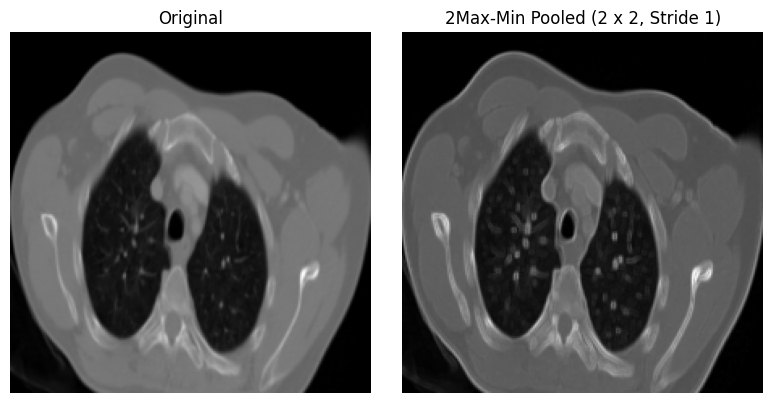

In [17]:
KERNEL_SIZE = 2
STRIDE = 1

# Get one batch
images, labels = next(iter(train_loader))

# Take first image
img = images[0:1]

pool = TwoMaxMinusMinPool2d(
    kernel_size=KERNEL_SIZE,
    stride=STRIDE
)

pool.eval()

with torch.no_grad():
    pooled = pool(img)

# Convert to numpy
img_np = img[0].cpu().numpy()
pooled_np = pooled[0].cpu().numpy()

# Select channel
ch = 0

fig, axs = plt.subplots(1, 2, figsize=(8, 4))

axs[0].imshow(img_np[ch], cmap="gray")
axs[0].set_title("Original")
axs[0].axis("off")

axs[1].imshow(pooled_np[ch], cmap="gray")
axs[1].set_title(
    f"2Max-Min Pooled "
    f"({KERNEL_SIZE} x {KERNEL_SIZE}, "
    f"Stride {STRIDE})"
)
axs[1].axis("off")

plt.tight_layout()
plt.show()

In [18]:
class CNN_ViT_Model(nn.Module):

    def __init__(self, num_classes):

        super().__init__()

        # =====================================================
        # 1. EFFICIENTNET-B0 BACKBONE
        # =====================================================

        pretrained_model = efficientnet_b0(
            weights=EfficientNet_B0_Weights.DEFAULT
        )

        # Include features[0] through features[6].
        # Output channels = 192

        self.efficientnet_backbone = nn.Sequential(
            *list(pretrained_model.features.children())[:7]
        )

        # All selected layers trainable

        for param in self.efficientnet_backbone.parameters():
            param.requires_grad = True

        ch_backbone = 192


        # =====================================================
        # 2. CNN TO ViT ADAPTER
        # =====================================================

        # Input:  [B, 192, 7, 7]
        # Output: [B, 16, 56, 56]

        self.cnn_to_vit_adapter = nn.Sequential(

            # First stage: 7x7

            nn.Conv2d(
                ch_backbone,
                64,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(64),

            nn.ReLU(inplace=True),

            # Upsample: 7x7 -> 14x14

            nn.Upsample(
                size=(14, 14),
                mode="bilinear",
                align_corners=False
            ),

            # Second stage: 14x14

            nn.Conv2d(
                64,
                32,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(32),

            nn.ReLU(inplace=True),

            # Upsample: 14x14 -> 28x28

            nn.Upsample(
                size=(28, 28),
                mode="bilinear",
                align_corners=False
            ),

            # Third stage: 28x28

            nn.Conv2d(
                32,
                16,
                kernel_size=3,
                padding=1
            ),

            nn.BatchNorm2d(16),

            nn.ReLU(inplace=True),

            # Upsample: 28x28 -> 56x56

            nn.Upsample(
                size=(56, 56),
                mode="bilinear",
                align_corners=False
            )

        )


        # =====================================================
        # 3. ViT ENCODER 1
        # =====================================================

        self.vit_encoder1 = VisionTransformer(

            img_size=56,
            patch_size=8,
            in_chans=16,

            num_classes=0,
            embed_dim=64,       # CHANGED: 48 -> 64

            depth=2,
            num_heads=4,
            mlp_ratio=2,

            qkv_bias=True,
            norm_layer=nn.LayerNorm
        )

        self.vit_encoder1.head = nn.Identity()


        # Enable overlapping patches
        # Patch size = 8
        # Stride = 4

        old_proj = self.vit_encoder1.patch_embed.proj

        self.vit_encoder1.patch_embed.proj = nn.Conv2d(

            old_proj.in_channels,
            old_proj.out_channels,

            kernel_size=8,
            stride=4,

            bias=old_proj.bias is not None
        )


        # Calculate number of patches

        img_h, img_w = self.vit_encoder1.patch_embed.img_size

        dummy = torch.zeros(
            1,
            old_proj.in_channels,
            img_h,
            img_w
        )

        with torch.no_grad():

            _, _, h, w = self.vit_encoder1.patch_embed.proj(
                dummy
            ).shape

        num_patches = h * w

        self.vit_encoder1.patch_embed.num_patches = num_patches


        # Reset positional embeddings

        self.vit_encoder1.pos_embed = nn.Parameter(
            torch.zeros(
                1,
                num_patches + 1,
                self.vit_encoder1.embed_dim
            )
        )

        nn.init.trunc_normal_(
            self.vit_encoder1.pos_embed,
            std=0.02
        )


        # =====================================================
        # 4. TWO MAX-MIN POOLING
        # =====================================================

        self.twomax_minus_min_pool = TwoMaxMinusMinPool2d(
            kernel_size=2,
            stride=1
        )


        # =====================================================
        # 5. ViT ENCODER 2
        # =====================================================

        self.vit_encoder2 = VisionTransformer(

            img_size=28,
            patch_size=7,
            in_chans=32,

            num_classes=0,
            embed_dim=64,       # CHANGED: 48 -> 64

            depth=2,
            num_heads=4,
            mlp_ratio=2,

            qkv_bias=True,
            norm_layer=nn.LayerNorm
        )

        self.vit_encoder2.head = nn.Identity()


        # =====================================================
        # 6. CNN PARALLEL HEAD
        # =====================================================

        # Input:  [B, 192, 7, 7]
        # Output: [B, 128]

        self.cnn_parallel_head = nn.Sequential(

            nn.Conv2d(
                ch_backbone,
                128,
                kernel_size=1
            ),

            nn.ReLU(inplace=True),

            nn.Conv2d(
                128,
                128,
                kernel_size=3,
                padding=0
            ),

            nn.BatchNorm2d(128),

            nn.ReLU(inplace=True),

            nn.AdaptiveAvgPool2d(1),

            nn.Flatten()
        )


        # =====================================================
        # 7. FINAL CLASSIFIER
        # =====================================================

        # ViT-1      = 64
        # ViT-2      = 64
        # CNN branch = 128
        #
        # Total      = 256

        self.classifier_head = nn.Linear(
            64 + 64 + 128,
            num_classes
        )


    # =========================================================
    # FORWARD PASS
    # =========================================================

    def forward(self, x):

        # -----------------------------------------------------
        # 1. EfficientNet-B0 backbone
        # -----------------------------------------------------

        features = self.efficientnet_backbone(x)

        # [B, 192, 7, 7]


        # -----------------------------------------------------
        # 2. CNN-to-ViT adapter
        # -----------------------------------------------------

        x = features

        intermediate = None

        for i, layer in enumerate(self.cnn_to_vit_adapter):

            x = layer(x)

            # Capture 32-channel feature map at 28x28

            if i == 7:
                intermediate = x

        # [B, 16, 56, 56]

        vit_input1 = x


        # -----------------------------------------------------
        # 3. ViT Encoder 1
        # -----------------------------------------------------

        vit_features1 = self.vit_encoder1(vit_input1)

        # [B, 64]


        # -----------------------------------------------------
        # 4. TwoMax-Min Pooling
        # -----------------------------------------------------

        vit_input2 = self.twomax_minus_min_pool(intermediate)

        # [B, 32, 27, 27]


        # -----------------------------------------------------
        # 5. Resize to 28x28
        # -----------------------------------------------------

        vit_input2 = F.interpolate(
            vit_input2,
            size=(28, 28),
            mode="bilinear",
            align_corners=False
        )

        # [B, 32, 28, 28]


        # -----------------------------------------------------
        # 6. ViT Encoder 2
        # -----------------------------------------------------

        vit_features2 = self.vit_encoder2(vit_input2)

        # [B, 64]


        # -----------------------------------------------------
        # 7. CNN Parallel Branch
        # -----------------------------------------------------

        cnn_features = self.cnn_parallel_head(features)

        # [B, 128]


        # -----------------------------------------------------
        # 8. Feature Fusion: 128:64:64
        # -----------------------------------------------------

        combined = torch.cat(
            [
                cnn_features,
                vit_features1,
                vit_features2
            ],
            dim=1
        )

        # [B, 256]


        # -----------------------------------------------------
        # 9. Classification
        # -----------------------------------------------------

        output = self.classifier_head(combined)

        return output

In [19]:
model = CNN_ViT_Model(
    num_classes=NUM_CLASSES
).to(device)

summary(
    model,
    input_size=(1, 3, 224, 224),
    col_names=[
        "input_size",
        "output_size",
        "num_params",
        "trainable"
    ]
)

Layer (type:depth-idx)                                  Input Shape               Output Shape              Param #                   Trainable
CNN_ViT_Model                                           [1, 3, 224, 224]          [1, 4]                    --                        True
├─Sequential: 1-1                                       [1, 3, 224, 224]          [1, 192, 7, 7]            --                        True
│    └─Conv2dNormActivation: 2-1                        [1, 3, 224, 224]          [1, 32, 112, 112]         --                        True
│    │    └─Conv2d: 3-1                                 [1, 3, 224, 224]          [1, 32, 112, 112]         864                       True
│    │    └─BatchNorm2d: 3-2                            [1, 32, 112, 112]         [1, 32, 112, 112]         64                        True
│    │    └─SiLU: 3-3                                   [1, 32, 112, 112]         [1, 32, 112, 112]         --                        --
│    └─Sequential: 2-2  

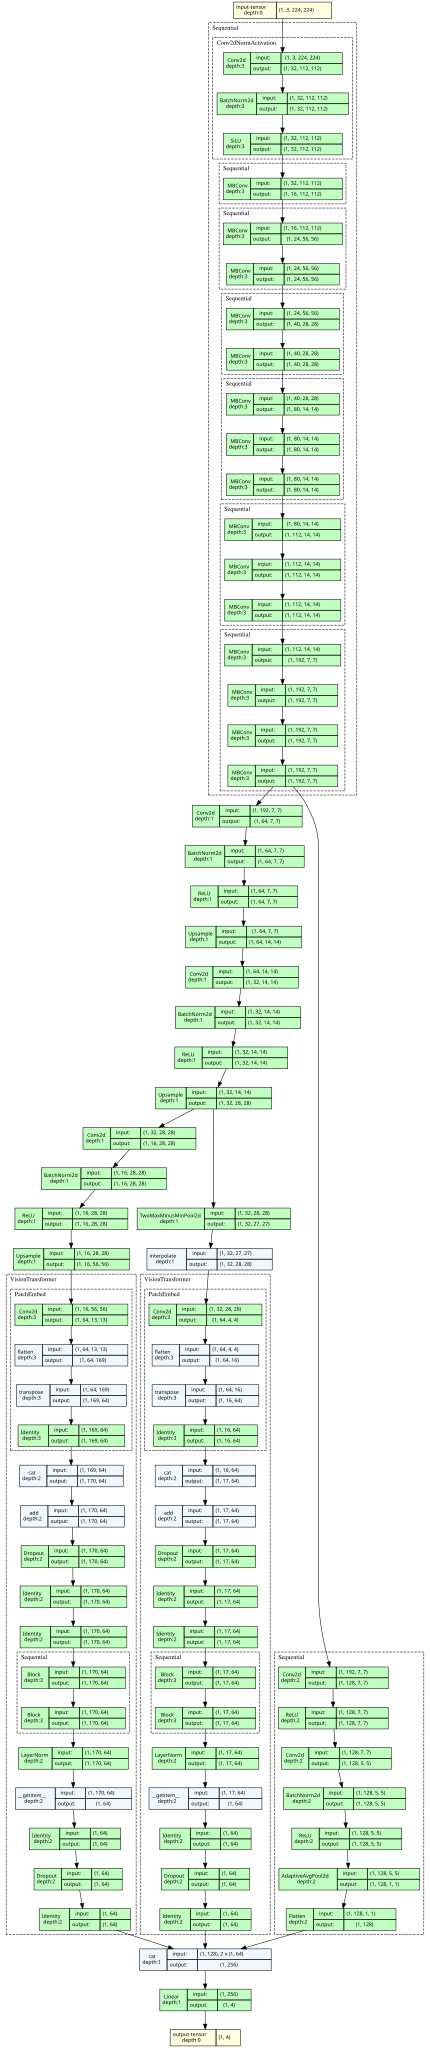

In [21]:
model.eval()

dummy_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

model_graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="EfficientNet192_CNN_ViT_Model",
    save_graph=False
)

svg_output = model_graph.visual_graph.pipe(format="svg")

display(SVG(svg_output))

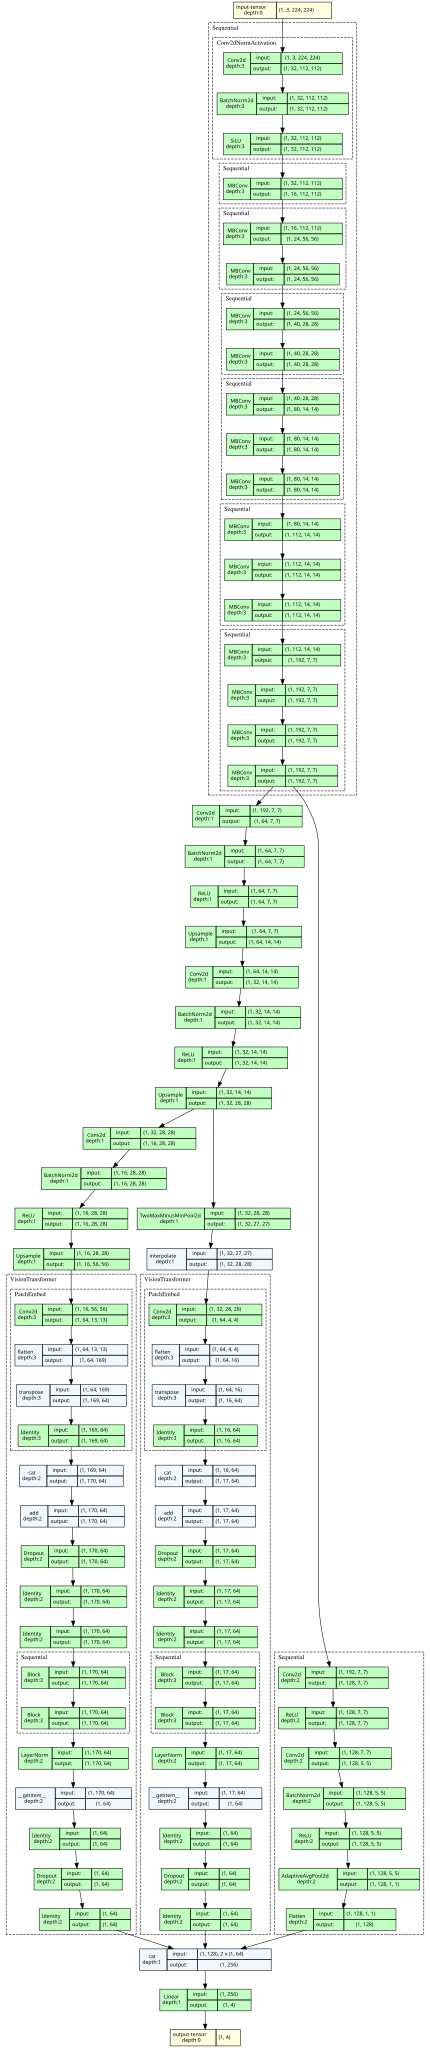

In [22]:
model.eval()

dummy_input = torch.randn(
    1, 3, 224, 224,
    device=device
)

model_graph = draw_graph(

    model,

    input_data=dummy_input,

    expand_nested=True,

    graph_name="EfficientNet_CNN_ViT_Model",

    save_graph=False
)

svg_output = model_graph.visual_graph.pipe(
    format="svg"
)

display(SVG(svg_output))

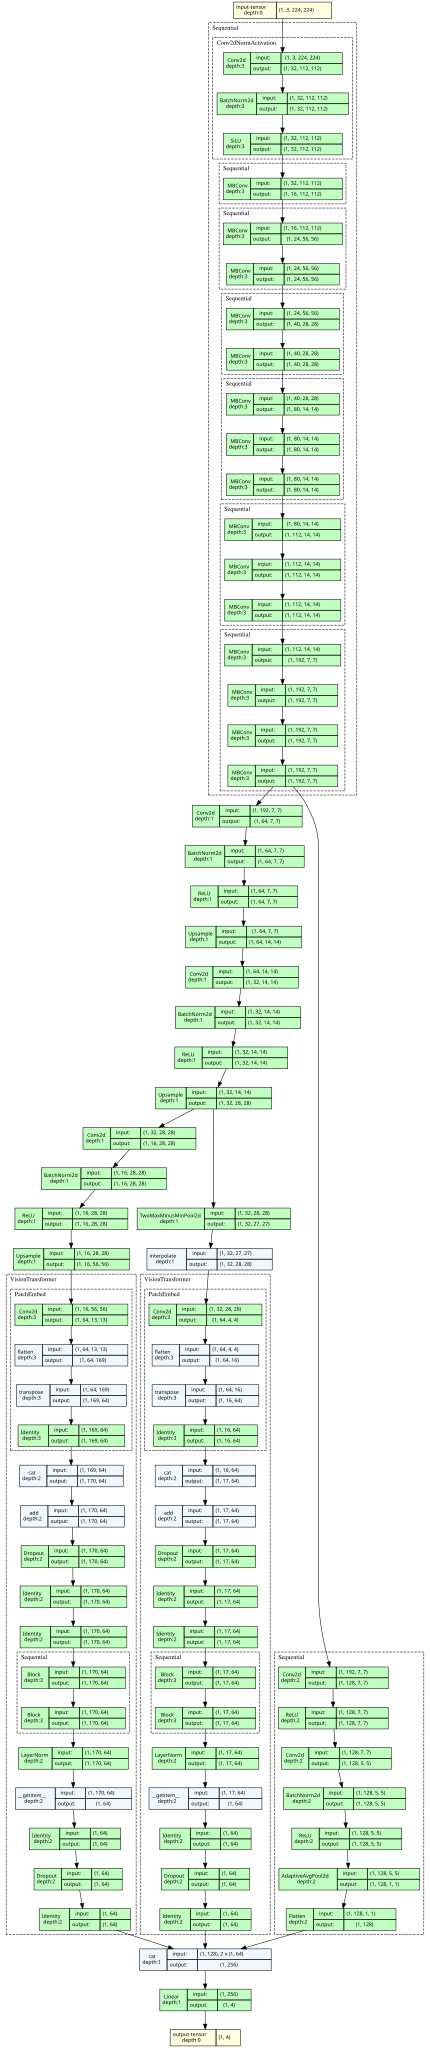

In [23]:
model.to(device)

# Dummy input (can adjust shape based on your model's expected input)
dummy_input = torch.randn(1, 3, 224, 224, device=device)

# Generate the graph — expand_nested=True if model has nested submodules
model_graph = draw_graph(
    model,
    input_data=dummy_input,
    expand_nested=True,
    graph_name="CNN_ViT_Model",
    save_graph=False  # We don't want to save, only display inline
)

# Render to SVG and display inline in the notebook
svg_output = model_graph.visual_graph.pipe(format='svg')
display(SVG(svg_output))

In [24]:
def custom_metrics(y_pred, y_true, loss):
    y_pred_classes = torch.argmax(y_pred, dim=1)

    y_true_numpy = y_true.cpu().numpy()
    y_pred_classes_numpy = y_pred_classes.cpu().numpy()
    accuracy = accuracy_score(y_true_numpy, y_pred_classes_numpy)

    precision = precision_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)
    recall = recall_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)
    f1 = f1_score(y_true_numpy, y_pred_classes_numpy, average='weighted', zero_division=0)

    cm = confusion_matrix(y_true_numpy, y_pred_classes_numpy)

    tn = cm[0, 0]
    fp = cm[0, 1:].sum()
    fn = cm[1:, 0].sum()
    tp = cm[1:, 1:].sum()

    specificity = tn / (tn + fp) if (tn + fp) != 0 else 0.0
    sensitivity = tp / (tp + fn) if (tp + fn) != 0 else 0.0

    mcc = matthews_corrcoef(y_true_numpy, y_pred_classes_numpy)

    num_classes = y_pred.shape[1]
    auc_scores = []

    for class_idx in range(num_classes):
        class_y_true = (y_true_numpy == class_idx).astype(np.float32)
        class_y_pred = y_pred[:, class_idx].cpu().numpy()

        # Skip AUC if only one class is present
        if np.unique(class_y_true).size < 2:
            continue
        try:
            auc_score = roc_auc_score(class_y_true, class_y_pred)
            auc_scores.append(auc_score)
        except ValueError:
            continue

    auc_avg = np.mean(auc_scores) if auc_scores else 0.0

    metrics = {
        "loss": loss,
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1_score": f1,
        "specificity": specificity,
        "sensitivity": sensitivity,
        "mcc": mcc,
        "auc": auc_avg,
    }

    return metrics

In [25]:
# Hyperparameters
num_epochs       = EPOCHS
initial_lr       = 2e-4
decay_start_epoch = 10
decay_factor     = 0.97

# Criterion, optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=initial_lr)

# Scheduler policy: 1.0 until epoch 11, then 0.98^(epoch - 11)
lr_lambda = lambda epoch: 1.0 if epoch < decay_start_epoch else decay_factor ** (epoch - decay_start_epoch)
scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_lambda=lr_lambda)

In [26]:
# Metrics initialization
metric_names = ["loss", "accuracy", "precision", "recall", "f1_score",
                "specificity", "sensitivity", "mcc", "auc"]
train_metrics_history = {metric: [] for metric in metric_names}
val_metrics_history = {metric: [] for metric in metric_names}

total_training_time = 0.0
total_validation_time = 0.0

# Training and validation loop
for epoch in range(num_epochs):
    start_time = time.time()

    # Training loop
    model.train()
    total_train_loss = 0.0
    all_train_predictions = []
    all_train_targets = []

    for batch_idx, (data, targets) in enumerate(tqdm(train_loader, desc=f"Training Epoch [{epoch + 1}/{num_epochs}]")):
        data = data.to(device)
        targets = targets.to(device)

        optimizer.zero_grad()
        outputs = model(data)
        loss = criterion(outputs, targets)
        loss.backward()
        optimizer.step()

        total_train_loss += loss.item()
        all_train_predictions.extend(outputs.detach().cpu().numpy())
        all_train_targets.extend(targets.detach().cpu().numpy())

    end_time = time.time()
    epoch_training_time = end_time - start_time
    total_training_time += epoch_training_time

    average_train_loss = total_train_loss / len(train_loader)
    all_train_predictions = np.array(all_train_predictions)
    all_train_targets = np.array(all_train_targets)

    train_metrics = custom_metrics(torch.tensor(all_train_predictions), torch.tensor(all_train_targets), average_train_loss)
    training_metrics_line = "Train Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in train_metrics.items()])
    print(training_metrics_line)

    for metric in metric_names:
        train_metrics_history[metric].append(train_metrics[metric])

    # Validation loop
    model.eval()
    total_val_loss = 0.0
    all_val_predictions = []
    all_val_targets = []
    start_val_time = time.time()

    with torch.no_grad():
        for batch_idx, (data, targets) in enumerate(tqdm(val_loader, desc="Validating Model")):
            data = data.to(device)
            targets = targets.to(device)

            outputs = model(data)
            loss = criterion(outputs, targets)
            total_val_loss += loss.item()

            all_val_predictions.extend(outputs.detach().cpu().numpy())
            all_val_targets.extend(targets.detach().cpu().numpy())

    end_val_time = time.time()
    epoch_validation_time = end_val_time - start_val_time
    total_validation_time += epoch_validation_time

    average_val_loss = total_val_loss / len(val_loader)
    all_val_predictions = np.array(all_val_predictions)
    all_val_targets = np.array(all_val_targets)

    val_metrics = custom_metrics(torch.tensor(all_val_predictions), torch.tensor(all_val_targets), average_val_loss)
    validation_metrics_line = "Val Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in val_metrics.items()])
    print(validation_metrics_line)

    for metric in metric_names:
        val_metrics_history[metric].append(val_metrics[metric])

    # Update LR via scheduler rather than manual mutliplication
    scheduler.step()

    current_lr = optimizer.param_groups[0]['lr']
    print(f"Epoch {epoch}/{num_epochs} — Loss: {loss.item():.4f} — LR: {current_lr:.6f}")

print(f"Total Training Time: {str(timedelta(seconds=total_training_time))}")
print(f"Total Validation Time: {str(timedelta(seconds=total_validation_time))}")

avg_training_time_per_epoch = total_training_time / (epoch + 1)
avg_validation_time_per_epoch = total_validation_time / (epoch + 1)
print(f"Average Training Time per Epoch: {str(timedelta(seconds=avg_training_time_per_epoch))}")
print(f"Average Validation Time per Epoch: {str(timedelta(seconds=avg_validation_time_per_epoch))}")

Training Epoch [1/25]: 100%|██████████| 103/103 [00:07<00:00, 14.59it/s]


Train Metrics - loss: 0.9071, accuracy: 0.6199, precision: 0.6270, recall: 0.6199, f1_score: 0.6124, specificity: 0.6667, sensitivity: 0.7177, mcc: 0.4852, auc: 0.8253


Validating Model: 100%|██████████| 12/12 [00:00<00:00, 19.82it/s]


Val Metrics - loss: 0.8483, accuracy: 0.6250, precision: 0.7252, recall: 0.6250, f1_score: 0.6192, specificity: 0.4348, sensitivity: 0.9388, mcc: 0.5545, auc: 0.9408
Epoch 0/25 — Loss: 0.1212 — LR: 0.000200


Training Epoch [2/25]: 100%|██████████| 103/103 [00:07<00:00, 13.09it/s]


Train Metrics - loss: 0.4293, accuracy: 0.8581, precision: 0.8592, recall: 0.8581, f1_score: 0.8580, specificity: 0.8410, sensitivity: 0.9258, mcc: 0.8086, auc: 0.9611


... (90 outputs left out)

Training Epoch [25/25]: 100%|██████████| 103/103 [00:07<00:00, 12.91it/s]


Train Metrics - loss: 0.0617, accuracy: 0.9804, precision: 0.9806, recall: 0.9804, f1_score: 0.9805, specificity: 0.9846, sensitivity: 0.9928, mcc: 0.9736, auc: 0.9992


Validating Model: 100%|██████████| 12/12 [00:00<00:00, 20.09it/s]

Val Metrics - loss: 0.4192, accuracy: 0.9028, precision: 0.9251, recall: 0.9028, f1_score: 0.9065, specificity: 0.9130, sensitivity: 1.0000, mcc: 0.8743, auc: 0.9742
Epoch 24/25 — Loss: 0.0056 — LR: 0.000127
Total Training Time: 0:03:03.287835
Total Validation Time: 0:00:15.924528
Average Training Time per Epoch: 0:00:07.331513
Average Validation Time per Epoch: 0:00:00.636981


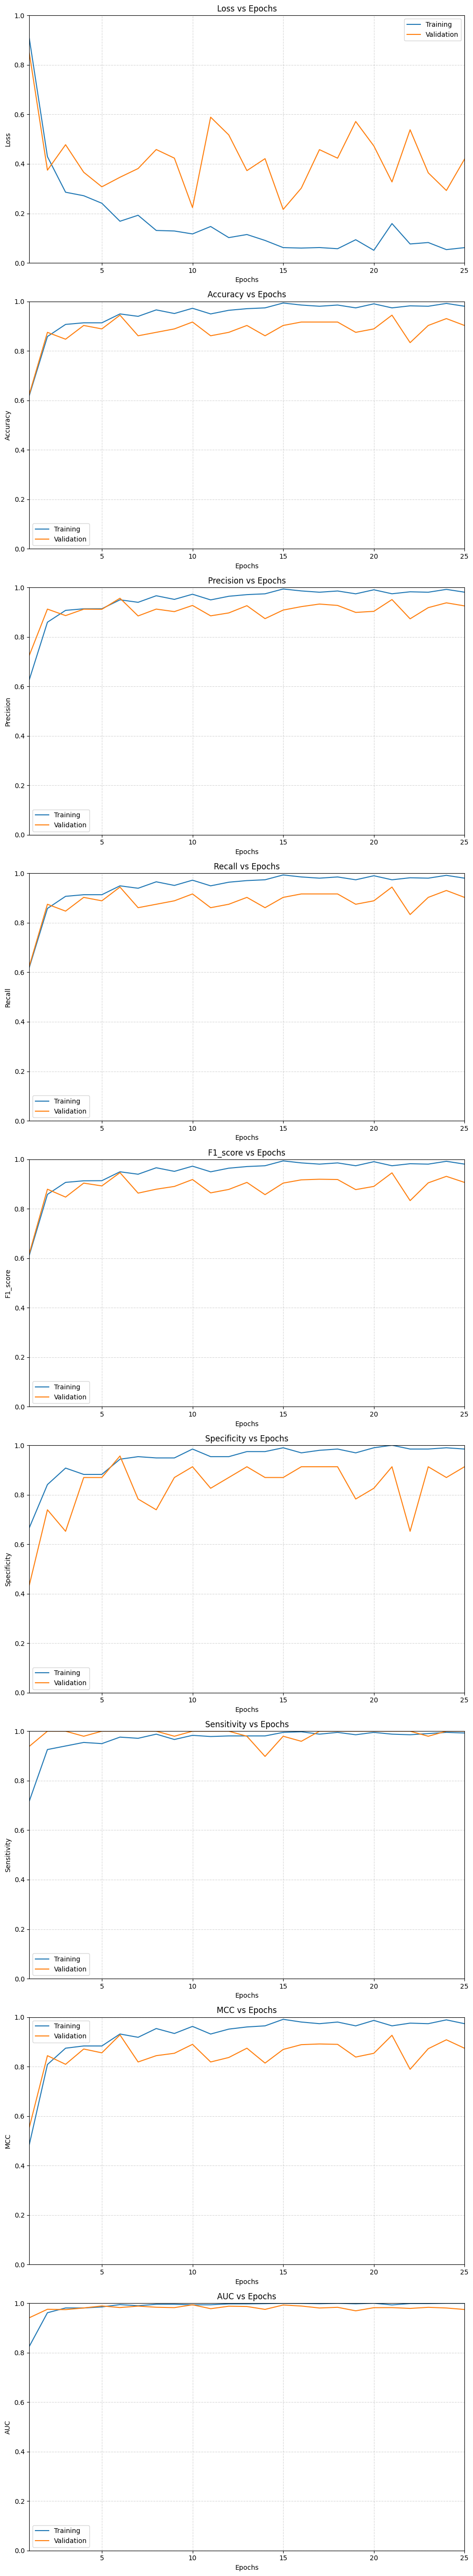

In [27]:
def plot_metrics(train_metrics_history, val_metrics_history, metric_names):
    num_metrics = len(metric_names)
    num_epochs = len(train_metrics_history[metric_names[0]])

    figure, axes = plt.subplots(num_metrics, figsize=(10, 6 * num_metrics))
    rng = range(1, num_epochs + 1)

    for ax, metric_name in zip(axes, metric_names):
        train_metric = train_metrics_history[metric_name]
        val_metric = val_metrics_history[metric_name]

        ax.plot(rng, train_metric, label="Training")
        ax.plot(rng, val_metric, label="Validation")
        ax.legend()
        ax.set_xlabel("Epochs")

        if metric_name in ("auc", "mcc"):
            ax.set_ylabel(metric_name.upper())
            ax.set_title(f"{metric_name.upper()} vs Epochs")
        else:
            ax.set_ylabel(metric_name.capitalize())
            ax.set_title(f"{metric_name.capitalize()} vs Epochs")

        max_metric = max(max(train_metric), max(val_metric))
        min_metric = min(min(train_metric), min(val_metric))
        y_max = math.ceil(max_metric)

        if min_metric > 0 or max_metric > 1:
            ax.set_ylim(0, y_max)
        else:
            ax.set_ylim(min_metric, y_max)

        ax.grid(True, linestyle='--', alpha=0.5)
        # Adjust xlim to avoid identical low and high limits.
        if num_epochs == 1:
            ax.set_xlim(0.5, 1.5)
        else:
            ax.set_xlim(1, num_epochs)

    plt.tight_layout()
    plt.show()

plot_metrics(train_metrics_history, val_metrics_history, metric_names)

In [28]:
# Testing loop
model.eval()
total_test_loss = 0.0
all_test_predictions = []
all_test_targets = []

with torch.no_grad():
    for batch_idx, (data, targets) in enumerate(tqdm(test_loader, desc="Testing Model")):
        data = data.to(device)
        targets = targets.to(device)

        outputs = model(data)
        loss = criterion(outputs, targets)
        total_test_loss += loss.item()

        all_test_predictions.extend(outputs.detach().cpu().numpy())
        all_test_targets.extend(targets.detach().cpu().numpy())

all_test_predictions = np.array(all_test_predictions)
all_test_targets = np.array(all_test_targets)

average_test_loss = total_test_loss / len(test_loader)
test_metrics = custom_metrics(torch.tensor(all_test_predictions), torch.tensor(all_test_targets), average_test_loss)
testing_metrics_line = "Test Metrics - " + ", ".join([f"{k}: {v:.4f}" for k, v in test_metrics.items()])
print(testing_metrics_line)

Testing Model: 100%|██████████| 53/53 [00:02<00:00, 23.80it/s]

Test Metrics - loss: 0.3747, accuracy: 0.9111, precision: 0.9315, recall: 0.9111, f1_score: 0.9138, specificity: 0.8167, sensitivity: 0.9949, mcc: 0.8843, auc: 0.9892


In [29]:
# Convert true labels and predictions to numpy
true_labels = np.array(all_test_targets)
predicted_labels = np.argmax(np.array(all_test_predictions), axis=1)

true_labels = true_labels.astype(int)
predicted_labels = predicted_labels.astype(int)

# Use dataset-derived class names (AUTO, SAFE)
classes = CLASS_NAMES

# Classification report
report = classification_report(
    true_labels,
    predicted_labels,
    target_names=classes,
    digits=4
)

# Accuracy
accuracy = accuracy_score(true_labels, predicted_labels)
num_errors = np.sum(true_labels != predicted_labels)

print(report)
print(
    f"There were {num_errors} errors in {len(predicted_labels)} tests "
    f"for an accuracy of {accuracy*100:.2f}%"
)


                                                  precision    recall  f1-score   support

      adenocarcinoma_left.lower.lobe_T2_N0_M0_Ib     0.9899    0.8167    0.8950       120
   large.cell.carcinoma_left.hilum_T2_N2_M0_IIIa     0.6986    1.0000    0.8226        51
                                          normal     1.0000    0.9815    0.9907        54
squamous.cell.carcinoma_left.hilum_T1_N2_M0_IIIa     0.9444    0.9444    0.9444        90

                                        accuracy                         0.9111       315
                                       macro avg     0.9082    0.9356    0.9132       315
                                    weighted avg     0.9315    0.9111    0.9138       315

There were 28 errors in 315 tests for an accuracy of 91.11%
